# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN:20 <br><br>

# Convolutional Neural Network
# TUGAS <br> <br>

# Tugas 1 — Modifikasi CNN CIFAR-10
## Langkah 1 — Pertahankan dataset CIFAR-10

In [24]:
# Import library
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [25]:
from tensorflow.keras import datasets

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

print("Dataset CIFAR-10 berhasil dimuat!")

Dataset CIFAR-10 berhasil dimuat!


In [26]:
print("Training Images:", train_images.shape)
print("Training Labels:", train_labels.shape)
print("Testing Images:", test_images.shape)
print("Testing Labels:", test_labels.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000, 1)


## Langkah 2 - Normalisasi dataset

In [27]:
# Normalisasi data CIFAR-10
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Normalisasi dataset berhasil!")

Normalisasi dataset berhasil!


## Langkah 3 - Menampilkan contoh gambar CIFAR-10

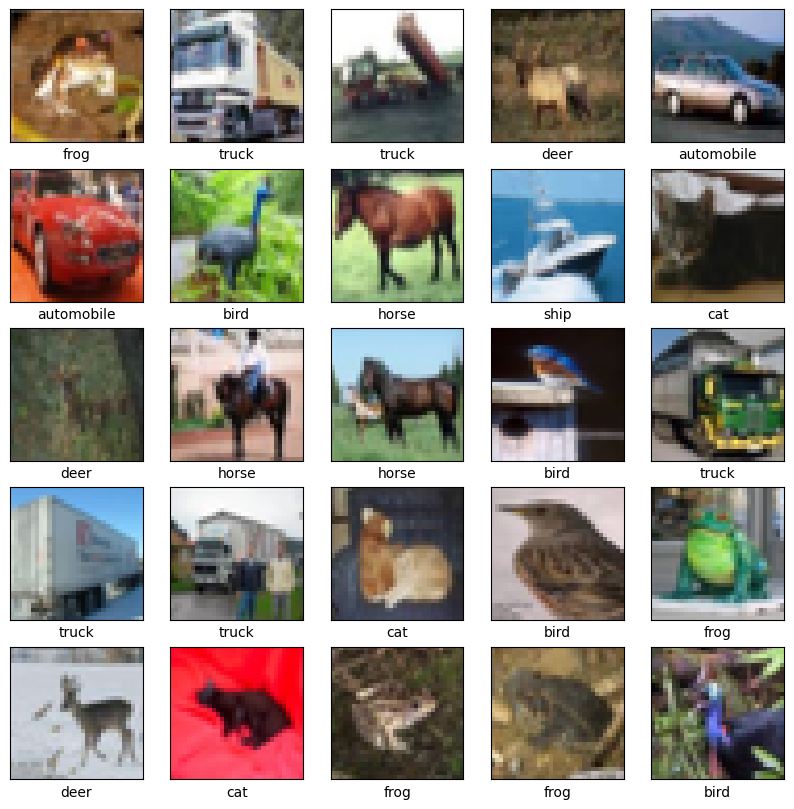

In [28]:
# Nama kelas CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Menampilkan 25 gambar
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])

plt.show()

## Langkah 4 — Modifikasi Arsitektur CNN

In [29]:
# Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Membuat model CNN
model_cifar = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10)
])

model_cifar.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## Langkah 5 - Compile Model CNN

In [30]:
# Compile model CNN CIFAR-10
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

print("Model berhasil di-compile!")

Model berhasil di-compile!


## Langkah 6 - Menyiapkan Callbacks

In [31]:
callbacks_cifar = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

## Langkah 7 - Training Model CNN CIFAR-10

In [32]:
history_cifar = model_cifar.fit(
    train_images,
    train_labels,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks_cifar
)

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 396s 551ms/step - accuracy: 0.3960 - loss: 1.6495 - val_accuracy: 0.4432 - val_loss: 1.5532 - learning_rate: 0.0010
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 436s 542ms/step - accuracy: 0.5129 - loss: 1.3541 - val_accuracy: 0.4896 - val_loss: 1.6734 - learning_rate: 0.0010
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 381s 541ms/step - accuracy: 0.5618 - loss: 1.2326 - val_accuracy: 0.5500 - val_loss: 1.4025 - learning_rate: 0.0010
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 379s 538ms/step - accuracy: 0.5969 - loss: 1.1464 - val_accuracy: 0.5952 - val_loss: 1.1557 - learning_rate: 0.0010
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 376s 534ms/step - accuracy: 0.6212 - loss: 1.0842 - val_accuracy: 0.6540 - val_loss: 0.9748 - learning_rate: 0.0010
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 385s 538ms/step - accuracy: 0.6438 - loss: 1.0248 - val_accuracy: 0.6744 - val_loss: 0.9511 - learning_rate: 0.0010
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 373s 530ms/step - accura

## Langkah 8 - Menampilkan grafik akurasi

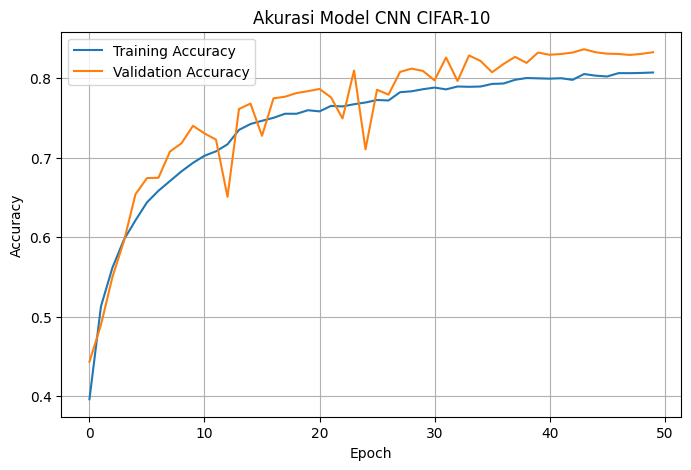

In [33]:
plt.figure(figsize=(8,5))

plt.plot(history_cifar.history['accuracy'], label='Training Accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Akurasi Model CNN CIFAR-10')
plt.legend()
plt.grid(True)
plt.show()

## Langkah 9 - Menampilkan grafik loss

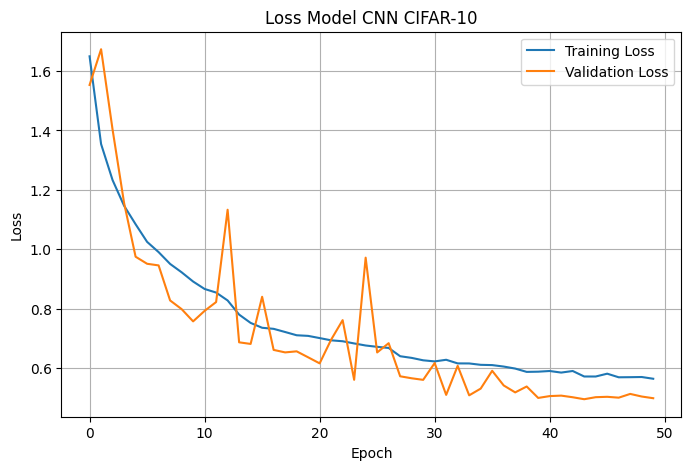

In [34]:
plt.figure(figsize=(8,5))

plt.plot(history_cifar.history['loss'], label='Training Loss')
plt.plot(history_cifar.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Model CNN CIFAR-10')
plt.legend()
plt.grid(True)
plt.show()

## Langkah 10 - Melakukan evaluasi menggunakan data testing

In [35]:
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(
    test_images,
    test_labels,
    verbose=2
)

print("Test Loss:", test_loss_cifar)
print("Test Accuracy:", test_acc_cifar)
print("Akurasi Testing: {:.2f}%".format(test_acc_cifar * 100))

313/313 - 19s - 60ms/step - accuracy: 0.8267 - loss: 0.5252
Test Loss: 0.525185763835907
Test Accuracy: 0.82669997215271
Akurasi Testing: 82.67%


## Langkah 11 - Menampilkan hasil prediksi gambar

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step


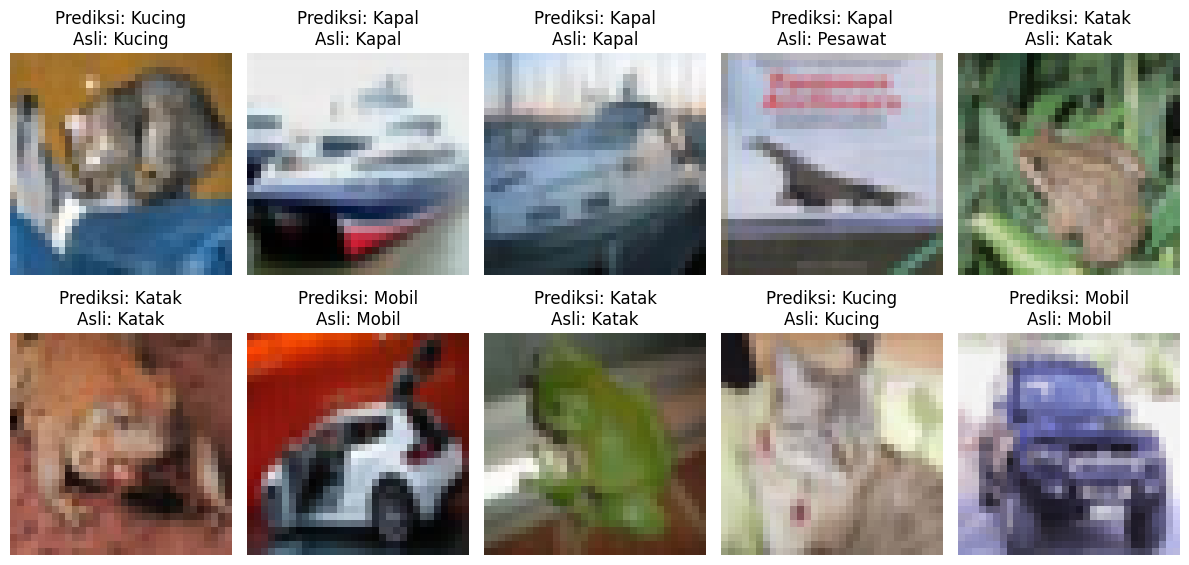

In [36]:
class_names = [
    'Pesawat', 'Mobil', 'Burung', 'Kucing', 'Rusa',
    'Anjing', 'Katak', 'Kuda', 'Kapal', 'Truk'
]

predictions_cifar = model_cifar.predict(test_images[:10])

plt.figure(figsize=(12,6))

for i in range(10):
    plt.subplot(2,5,i+1)

    plt.imshow(test_images[i])

    predicted_label = np.argmax(predictions_cifar[i])
    actual_label = test_labels[i][0]

    plt.title(
        "Prediksi: {}\nAsli: {}".format(
            class_names[predicted_label],
            class_names[actual_label]
        )
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

# Kesimpulan:

Model CNN dimodifikasi agar akurasi testing melebihi 80%. Perubahan yang dilakukan:

1. **Arsitektur lebih dalam**: terdapat 3 blok konvolusi (32, 64, dan 128 filter), masing-masing berisi 2 layer Conv2D, sehingga model dapat mempelajari fitur yang lebih kompleks.
2. **Batch Normalization**: ditambahkan setelah setiap Conv2D untuk menstabilkan dan mempercepat proses training.
3. **Dropout bertingkat (0.2, 0.3, 0.4)**: mengurangi overfitting, terutama pada blok yang lebih dalam.
4. **Data augmentation** (random flip, rotation, dan zoom): menambah variasi data training sehingga model lebih mampu menggeneralisasi.
5. **Global Average Pooling**: menggantikan Flatten agar jumlah parameter lebih sedikit dan risiko overfitting lebih kecil.
6. **Callback**: EarlyStopping (memantau `val_accuracy`, mengembalikan bobot terbaik) dan ReduceLROnPlateau (menurunkan learning rate saat `val_loss` tidak membaik).

**Hasil:** akurasi testing sebesar **82,67%**, sehingga memenuhi target lebih dari 80%.

# Tugas 2 - Membuat model CNN untuk klasifikasi dataset MNIST
## Langkah 1 - Memuat dataset MNIST

In [37]:
(train_images_mnist, train_labels_mnist), (test_images_mnist, test_labels_mnist) = datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## Langkah 2 - Memeriksa bentuk dataset

In [38]:
print("Bentuk data training:", train_images_mnist.shape)
print("Bentuk label training:", train_labels_mnist.shape)

print("Bentuk data testing:", test_images_mnist.shape)
print("Bentuk label testing:", test_labels_mnist.shape)

Bentuk data training: (60000, 28, 28)
Bentuk label training: (60000,)
Bentuk data testing: (10000, 28, 28)
Bentuk label testing: (10000,)


## Langkah 3 - Melakukan normalisasi dan mengubah bentuk data

In [39]:
# Normalisasi data
train_images_mnist = train_images_mnist / 255.0
test_images_mnist = test_images_mnist / 255.0

# Mengubah bentuk data menjadi 28x28 dengan 1 channel
train_images_mnist = train_images_mnist.reshape(-1, 28, 28, 1)
test_images_mnist = test_images_mnist.reshape(-1, 28, 28, 1)

print("Bentuk data training setelah preprocessing:", train_images_mnist.shape)
print("Bentuk data testing setelah preprocessing:", test_images_mnist.shape)

Bentuk data training setelah preprocessing: (60000, 28, 28, 1)
Bentuk data testing setelah preprocessing: (10000, 28, 28, 1)


## Langkah 4 - Menampilkan contoh gambar MNIST

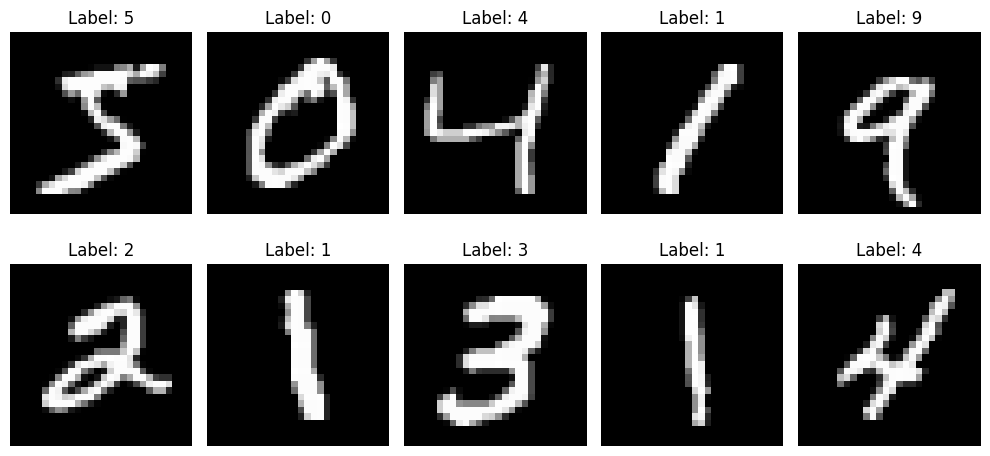

In [40]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images_mnist[i].squeeze(), cmap='gray')
    plt.title("Label: {}".format(train_labels_mnist[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

## Langkah 5 - Membuat arsitektur model CNN MNIST

In [41]:
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 6 - Melakukan compile model

In [42]:
model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model CNN MNIST berhasil di-compile!")

Model CNN MNIST berhasil di-compile!


## Langkah 7 - Melakukan training model MNIST

In [43]:
history_mnist = model_mnist.fit(
    train_images_mnist,
    train_labels_mnist,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 53ms/step - accuracy: 0.9346 - loss: 0.2090 - val_accuracy: 0.9858 - val_loss: 0.0496
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9789 - loss: 0.0686 - val_accuracy: 0.9893 - val_loss: 0.0376
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accuracy: 0.9843 - loss: 0.0516 - val_accuracy: 0.9885 - val_loss: 0.0403
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accuracy: 0.9876 - loss: 0.0412 - val_accuracy: 0.9910 - val_loss: 0.0312
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 51ms/step - accuracy: 0.9899 - loss: 0.0318 - val_accuracy: 0.9892 - val_loss: 0.0354
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 50ms/step - accuracy: 0.9912 - loss: 0.0275 - val_accuracy: 0.9902 - val_loss: 0.0316
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9925 - loss: 0.0229 - val_accuracy: 0.9920 - val_loss: 0.0289
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9936 - loss: 0.0197 - 

## Langkah 8 - Menampilkan grafik akurasi

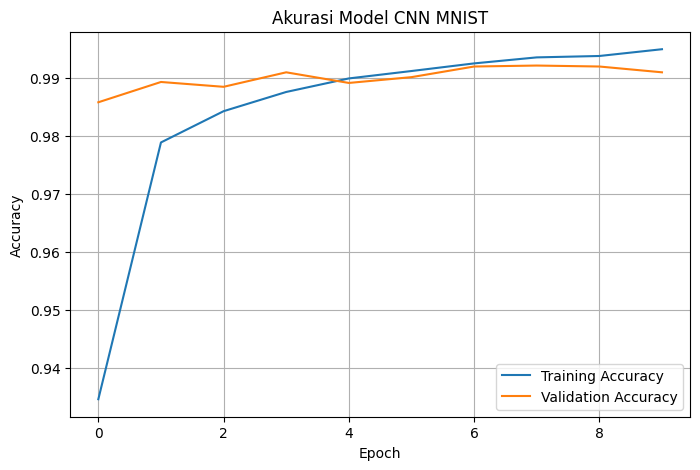

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(history_mnist.history['accuracy'], label='Training Accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Akurasi Model CNN MNIST')
plt.legend()
plt.grid(True)
plt.show()

## Langkah 9 - Menampilkan grafik loss

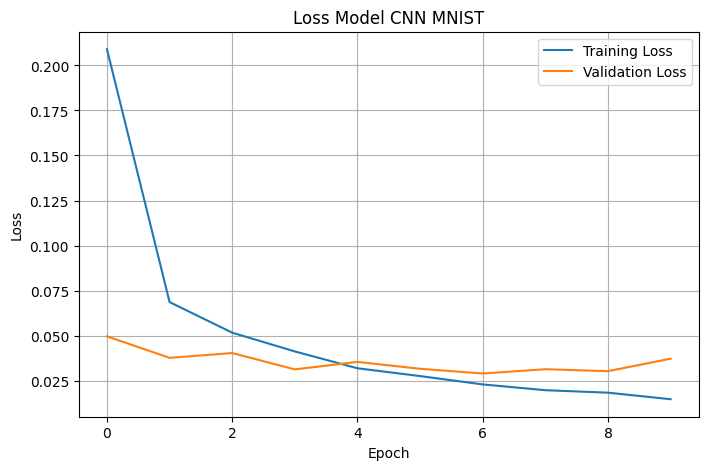

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(history_mnist.history['loss'], label='Training Loss')
plt.plot(history_mnist.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Model CNN MNIST')
plt.legend()
plt.grid(True)
plt.show()

## Langkah 10 - Melakukan evaluasi menggunakan data testing

In [46]:
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(
    test_images_mnist,
    test_labels_mnist,
    verbose=2
)

print("Test Loss:", test_loss_mnist)
print("Test Accuracy:", test_acc_mnist)
print("Akurasi Testing MNIST: {:.2f}%".format(test_acc_mnist * 100))

313/313 - 3s - 9ms/step - accuracy: 0.9915 - loss: 0.0314
Test Loss: 0.03136437013745308
Test Accuracy: 0.9915000200271606
Akurasi Testing MNIST: 99.15%


## Langkah 11 - Menampilkan hasil prediksi gambar MNIST

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step


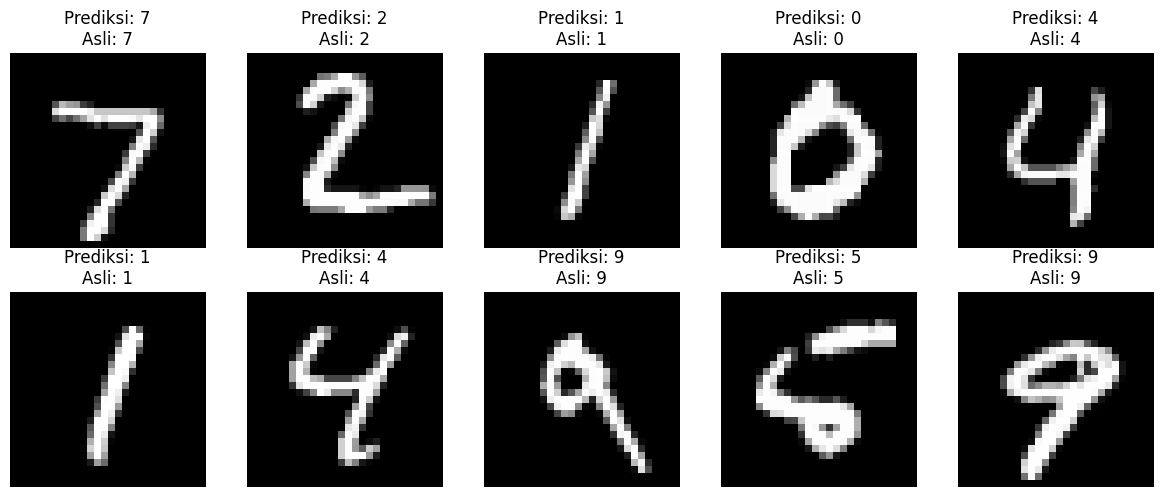

In [47]:
predictions_mnist = model_mnist.predict(test_images_mnist[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(test_images_mnist[i].squeeze(), cmap='gray')

    predicted_label = np.argmax(predictions_mnist[i])
    actual_label = test_labels_mnist[i]

    plt.title(
        "Prediksi: {}\nAsli: {}".format(
            predicted_label,
            actual_label
        )
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

# Kesimpulan:

Dataset MNIST berisi gambar angka tulisan tangan 0–9 berukuran 28x28 piksel (grayscale). Data dinormalisasi ke rentang 0–1 dan diubah bentuknya menjadi (28, 28, 1).

Arsitektur model:
- 2 blok Conv2D (32 dan 64 filter, kernel 3x3, aktivasi ReLU), masing-masing diikuti MaxPooling 2x2 untuk mengekstraksi fitur dan memperkecil ukuran data.
- Flatten, lalu Dense 128 neuron (ReLU) dengan Dropout 0.3 untuk mengurangi overfitting.
- Dense 10 neuron dengan aktivasi softmax sebagai output untuk 10 kelas.

Model dikompilasi dengan optimizer Adam dan loss `sparse_categorical_crossentropy`, lalu dilatih selama 10 epoch.

**Hasil:** akurasi testing sebesar **99,15%**, yang menunjukkan model mampu mengenali angka tulisan tangan dengan sangat baik.